In [1]:
import pandas as pd

listings=pd.read_csv('listings.csv.gz')
reviews=pd.read_csv('reviews.csv.gz')





In [2]:
"""A2 | Exploration et dictionnaire 3 pts
• Pour listings et reviews, présentez :
– le nombre de lignes et de colonnes ;
– les types ;
– le pourcentage de valeurs manquantes par colonne ;
– le nombre de valeurs distinctes.

• Repérez les colonnes entièrement vides dans votre snapshot : cela varie d’une ville à
l’autre."""


#le nombre de lignes et de colonnes 

review_shape=reviews.shape
listings_shape=listings.shape

#les types

review_dtype=reviews.dtypes.value_counts()
listings_dtype=listings.dtypes.value_counts()

#resumé
def resume(df):
    infos = {'lignes': df.shape[0], 'colonnes': df.shape[1]}
    infos.update(df.dtypes.astype(str).value_counts().to_dict())   # nb de colonnes par type
    return infos

recap = pd.DataFrame({'Table reviews': resume(reviews), 'Table listings': resume(listings)}).fillna(0).astype(int)
display(recap)

,Table reviews,Table listings
lignes,577646,10750
colonnes,6,90
int64,3,24
object,3,29
float64,0,37


In [3]:
 # % valeurs manquantes "listings"

valeurs_manquantesL=(listings.isna().mean() * 100).round(1).sort_values(ascending=False)
valeurs_manquantesL.to_string()
n_empty=listings.isna().all().sum()
empty_cols=list(valeurs_manquantesL.index[valeurs_manquantesL==100])


def categorie(pct):
    if pct == 0:
        return "Complete"
    elif pct < 40:
        return "Mostly complete"
    elif pct < 100:
        return "Almost empty"
    elif pct==100:
        return "Empty"

categories = valeurs_manquantesL.apply(categorie)


ordre = ['Complete', 'Mostly complete', 'Almost empty', 'Empty']

categories.value_counts().reindex(ordre).to_frame('nb_colonnes')



groupes = pd.cut(valeurs_manquantesL,
                 bins=[-1, 0, 10, 50, 99.99, 100],
                 labels=['0 % (complètes)', '0–10 %', '10–50 %', '50–99 %', '100 % (vides)'])
synthese = pd.DataFrame({'% manquants': valeurs_manquantesL, 'groupe': groupes})

recap = synthese.groupby('groupe', observed=False).agg(
    nb_colonnes=('% manquants', 'count'),
    colonnes=('% manquants', lambda s: ', '.join(s.index))
)
with pd.option_context('display.max_colwidth', None):
    display(recap)
    

,nb_colonnes,colonnes
groupe,,
0 % (complètes),45,"availability_60, availability_365, calendar_last_scraped, calculated_host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, availability_90, number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, availability_eoy, number_of_reviews_ly, estimated_occupancy_l365d, availability_30, calculated_host_listings_count_shared_rooms, id, maximum_nights_avg_ntm, hosts_time_as_host_years, scrape_id, last_scraped, name, description, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_name, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_months, minimum_nights_avg_ntm, host_is_superhost, host_picture_url, host_listings_count, host_has_profile_pic, host_identity_verified, neighbourhood_cleansed, latitude, longitude, property_type, room_type, accommodates, listing_url, amenities"
0–10 %,21,"review_scores_cleanliness, reviews_per_month, first_review, last_review, review_scores_rating, review_scores_accuracy, review_scores_checkin, review_scores_communication, review_scores_value, review_scores_location, license, beds, maximum_maximum_nights, minimum_maximum_nights, maximum_minimum_nights, minimum_minimum_nights, maximum_nights, minimum_nights, has_availability, bedrooms, bathrooms_text"
10–50 %,9,"host_about, price_quote_total_price, price_quote_price_per_night, price, estimated_revenue_l365d, price_quote_checkin_date, price_quote_checkout_date, price_quote_raw, host_location"
50–99 %,1,source
100 % (vides),14,"host_verifications, bathrooms, host_acceptance_rate, host_response_rate, host_response_time, host_neighbourhood, host_total_listings_count, calendar_updated, host_since, neighbourhood, host_thumbnail_url, neighbourhood_group_cleansed, instant_bookable, neighborhood_overview"


In [4]:
# % valeurs manquantes reviews


valeurs_manquantesR=(reviews.isna().mean() * 100).round(2).sort_values(ascending=False)
valeurs_manquantesR.to_string()
n_empty=reviews.isna().all().sum()

display(pd.DataFrame({"colonne": (reviews.isna().mean() * 100).round(2).index,
                      "% de v.manquante": (reviews.isna().mean() * 100).round(2).values}))




,colonne,% de v.manquante
0,listing_id,0.00
1,id,0.00
2,date,0.00
3,reviewer_id,0.00
4,reviewer_name,0.00
5,comments,0.17


In [5]:
#nombre de valeurs distinctes: listings, reviews

valeurs_dis_list=listings.nunique()

valeurs_dis_rev=reviews.nunique()

with pd.option_context('display.max_rows', None):
    display(pd.DataFrame(valeurs_dis_list.sort_values(ascending=False), columns=['Valeurs uniques']))

display(pd.DataFrame(valeurs_dis_rev.sort_values(ascending=False),columns=['Valeurs uniques']))

,Valeurs uniques
id,10612
listing_url,10612
picture_url,10561
name,10248
description,10091
amenities,10048
host_id,9231
host_url,9231
host_profile_id,9231
host_profile_url,9231


,Valeurs uniques
id,554973
comments,536780
reviewer_id,533234
reviewer_name,71244
listing_id,11325
date,6659


In [6]:
#dictionnaire de données pour les colonnes que vous retenez (25 à 35). Pour
#chaque colonne : nom, signification, type d’origine, type cible, unité, pourcentage de manquants, décision (garder, transformer, écarter)

#columns, draft
colonnes=[
'number_of_reviews_ltm',
'last_review',
'availability_365',
'calculated_host_listings_count',
'room_type',
'price',
'accommodates',
'hosts_time_as_host_months',
 'hosts_time_as_host_years',
'amenities',
'minimum_nights',
'license',
'number_of_reviews_ltm',
'last_review',
'availability_365',
'host_id',
'id',
'estimated_revenue_l365d',
'estimated_occupancy_l365d',
'hosts_time_as_host_months',
'neighbourhood_cleansed',
'bedrooms',
'last_scraped',
'host_is_superhost',
'first_review',
'bathrooms_text'
]
print(len(colonnes))

# remove doubles 

colonnes=list(dict.fromkeys(i.strip ()for i in colonnes))
len(colonnes)



26


22

In [8]:
#nouvelle table 'listings' sans colonnes vides
## drop 100% empty columns -77 columns now

new_table=listings.drop(columns=empty_cols)


round(new_table.notna().mean()*100,1).sort_values(ascending=True)


print(round(new_table.notna().mean()*100,1).sort_values(ascending=True).to_string())




source                                           46.7
host_about                                       53.0
price_quote_price_per_night                      57.0
price_quote_total_price                          57.0
estimated_revenue_l365d                          57.1
price                                            57.1
price_quote_raw                                  58.3
price_quote_checkout_date                        58.3
price_quote_checkin_date                         58.3
host_location                                    85.6
review_scores_cleanliness                        90.5
review_scores_location                           90.6
review_scores_checkin                            90.6
review_scores_accuracy                           90.6
review_scores_rating                             90.6
first_review                                     90.6
review_scores_value                              90.6
review_scores_communication                      90.6
last_review                 

In [15]:
"""A3: conversion
""price=objet(texte), convertir en float et verifier que rien n'est perdu"""

colonnes=list(dict.fromkeys(i.strip ()for i in colonnes))

def convertir_prix(x):
    if pd.isna(x):
        return None
    s = str(x).strip()
    s = s.replace('CAD', '').replace('dollars', '').replace('$', '').replace(' ', '')
    if ',' in s and '.' in s:         
        s = s.replace(',', '')
    elif ',' in s:                    
        s = s.replace(',', '.')
    try:
        return float(s)
    except ValueError:
        return None

new_table['price']=new_table['price'].apply(convertir_prix)

price_values1=listings['price'].isna().sum()
price_values2=new_table['price'].isna().sum()


summary_table={'avant':[price_values1,listings['price'].dtype ], 
               'apres':[price_values2,new_table['price'].dtype] }

print("Convertir colonne 'price' en float")

pd.DataFrame(summary_table,index=['lignes', 'dtype'])

Convertir colonne 'price' en float


,avant,apres
lignes,4614,4614
dtype,object,float64


In [14]:
"""'host_response_rate', 'host_acceptance_rate' sont vides"""

"""host_is_superhost-not empty contains mostly t and f but also'no, faux, fasleetc...),
instant_bookable-vide-empty"""



def convertir_truefalse(i):
    i=str(i)
    if i=='Faux' or i=='no' or i=='FALSE'or i=='0':        
        i = 'f'
    elif  i=='Vrai' or i=='yes' or i=='TRUE'or i=='1':
        i = 't'
    return i 

#restore the column if i repeat the conversion

new_table['host_is_superhost'] = listings.loc[new_table.index, 'host_is_superhost']

new_table['host_is_superhost']=new_table['host_is_superhost'].apply(convertir_truefalse)
new_table['host_is_superhost'] = new_table['host_is_superhost'].map({'t': True, 'f': False}).astype('boolean')


superhost_values_before=listings['host_is_superhost'].value_counts(dropna=False).count()
superhost_values_after=new_table['host_is_superhost'].value_counts(dropna=False).count()

dtype_before=listings['host_is_superhost'].dtype
dtype_after=new_table['host_is_superhost'].dtype


total_values_before=listings['host_is_superhost'].value_counts(dropna=False).sum()
total_values_after=new_table['host_is_superhost'].value_counts(dropna=False).sum()

print("Convertir colonne 'host_is_superhost' ")
summary=pd.DataFrame({'dtype':[dtype_before,dtype_after], 
                      'v_dist':[superhost_values_before,superhost_values_after],
                      'total':[total_values_before,total_values_after]},index=['avant', 'apres'])

display(summary)

Convertir colonne 'host_is_superhost' 


,dtype,v_dist,total
avant,object,10,10750
apres,boolean,2,10750


In [16]:
"""Dates: last_scraped,first_review,last_review-all not empty"""

cols=['last_scraped', 'first_review', 'last_review']
summary_table={ }

for i in cols:
    avant=new_table[i].count()#count how many values in each col to make sure we havent lost anyth
    dtype1=listings[i].dtype
    new_table[i]=pd.to_datetime(new_table[i],format='mixed',dayfirst=True,errors='coerce' )
    apres=new_table[i].count()
    dtype2=new_table[i].dtype
    summary_table[i]={'avant': avant, 'après': apres, 'dtype avant':dtype1  ,'dtype après':dtype2   }



print("Convertir des dates qui sont stockées en texte (object), avec deux formats mélangés")
pd.DataFrame(summary_table).T



Convertir des dates qui sont stockées en texte (object), avec deux formats mélangés


,avant,après,dtype avant,dtype après
last_scraped,10750,10750,object,datetime64[ns]
first_review,9735,9735,object,datetime64[ns]
last_review,9735,9735,object,datetime64[ns]


In [17]:
"""A3 — bathrooms_text : texte → nombre de salles de bain + indicateur 'partagée'
Exemples de valeurs : '1 bath', '1.5 baths', '1 shared bath', 'Half-bath'
- nmb_bathrooms : on extrait le nombre ; 'half' (sans chiffre) → 0.5
- partage : True si la salle de bain est partagée ('shared')
Contrôle : nombre de textes renseignés dont on n'a pas pu extraire de nombre."""

new_table['nmb_bathrooms'] = new_table['bathrooms_text'].str.extract(r'(\d+\.?\d*)')[0].astype(float)
half = new_table['bathrooms_text'].str.contains("half", case=False, na=False)
new_table.loc[half, 'nmb_bathrooms'] = 0.5
new_table['partage'] = new_table['bathrooms_text'].str.contains('shared', case=False, na=False)

# contrôle : texte présent mais nombre non extrait = valeur illisible
illisibles = (new_table['bathrooms_text'].notna() & new_table['nmb_bathrooms'].isna()).sum()

print(f"Textes renseignés          : {new_table['bathrooms_text'].notna().sum()}")
print(f"Valeurs illisibles         : {illisibles}")
print(f"Demi-salles de bain (0.5)  : {half.sum()}")
print(f"Salles de bain partagées   : {new_table['partage'].sum()}")
display(new_table[['bathrooms_text', 'nmb_bathrooms', 'partage']].head())

colonnes.extend(['nmb_bathrooms', 'partage'])

Textes renseignés          : 10742
Valeurs illisibles         : 0
Demi-salles de bain (0.5)  : 47
Salles de bain partagées   : 560


,bathrooms_text,nmb_bathrooms,partage
0,1 bath,1.0,False
1,2 baths,2.0,False
2,1 bath,1.0,False
3,1 bath,1.0,False
4,1 bath,1.0,False


In [19]:
"""amenities : liste écrite comme une chaîne (texte) --> liste Python, puis nombre d'équipements"""

import json
new_table['amenities_'] = new_table['amenities'].apply(json.loads)  
new_table['n_amenities'] = new_table['amenities_'].apply(len)       

print("Nombre d'équipements : min", new_table['n_amenities'].min(), ", max", new_table['n_amenities'].max())
print("Annonces sans équipement :", (new_table['n_amenities'] == 0).sum())
display(new_table[['amenities_', 'n_amenities']].head())

colonnes.extend(['amenities_', 'n_amenities'])

Nombre d'équipements : min 0 , max 99
Annonces sans équipement : 5


,amenities_,n_amenities
0,"[Bed linens, Private patio or balcony, Canal v...",40
1,"[Bed linens, Canal view, Smoke alarm, Mini fri...",34
2,"[Bed linens, Private patio or balcony, Smoke a...",36
3,"[Bed linens, Private patio or balcony, Smoke a...",33
4,"[Kitchen, Dedicated workspace, TV, Smoke alarm...",6


In [20]:
"""Modalités :
room_type (libellés écrits de plusieurs façons, ex. 'ENTIRE HOME/APT', 'Private') --> une seule écriture par modalité"""

new_table['room_type'] = new_table['room_type'].str.lower()          # tout en minuscules

r = {'entire home': 'entire home/apt', 'private': 'private room'}     # libellés incomplets --> libellé complet
new_table['room_type'] = new_table['room_type'].replace(r)

n_before = listings['room_type'].value_counts().sum()
cat_before = listings['room_type'].value_counts().count()

n_after = new_table['room_type'].value_counts().sum()
cat_after = new_table['room_type'].value_counts().count()

summary = pd.DataFrame({'avant': [n_before, cat_before], 'apres': [n_after, cat_after]},
                       index=['Valeurs renseignées', 'Libellés distincts'])
display(summary)

print("Modalités finales :")
display(new_table['room_type'].value_counts().to_frame())




,avant,apres
Valeurs renseignées,10750,10750
Libellés distincts,10,4


Modalités finales :


,count
room_type,
entire home/apt,8689
private room,2014
hotel room,24
shared room,23


In [18]:
""" A4 | Valeurs manquantes 
• Pour chaque colonne retenue qui contient des manquants, choisissez une stratégie parmi
celles vues en cours :
• Présentez vos choix dans un tableau : colonne, pourcentage de manquants, stratégie,
justification.
• Interrogez-vous sur la cause des manquants. Exemple : un prix manquant peut
correspondre à une annonce non réservable au moment du snapshot."""



#je creer une nouvelle table à partir des colonnes j'ai selectionné avant

colonnes=list(dict.fromkeys(colonnes))
nouvelle_table=new_table[colonnes].copy()

#valeurs manq apparaissent des les colonnes suivantes: 'last_review' ,'first_review','price',
#'estimated_revenue_l365d', "minimum_nights",'license','bedrooms', 'bathrooms_text','nmb_bathrooms'

manquants = pd.DataFrame({
    'nb_manquants': nouvelle_table.isna().sum(),
    '% manquants' : round(nouvelle_table.isna().mean() *100 ,2)
})
manquants[manquants['nb_manquants'] > 0].sort_values('nb_manquants',ascending=False)

strategies = {
    'price':                   'NaN conservés + indicateur prix_renseigne',
    'estimated_revenue_l365d': 'NaN conservés (filtrer avec prix_renseigne)',
    'last_review':             'NaN conservés + indicateur a_des_avis',
    'first_review':            'NaN conservés + indicateur a_des_avis',
    'license':                 'Nouvelle variable statut_licence (non renseigné / exempté / renseigné)',
    'minimum_nights':          'Imputation par minimum_nights_avg_ntm (même annonce)',
    'bedrooms':                'Private room → 1 ; entire home/apt → NaN conservés',
    'bathrooms_text':          'NaN conservés (variable brute)',
    'nmb_bathrooms':           'Imputation par 1',
}

justifications = {
    'price':                   'Prix absent si calendrier fermé (92 % des cas) ; imputer fausserait les revenus',
    'estimated_revenue_l365d': 'Mêmes lignes que price (revenu = nuits × prix)',
    'last_review':             "Annonce sans aucun avis : pas de date à inventer",
    'first_review':            "Annonce sans aucun avis : pas de date à inventer",
    'license':                 "Le manquant est une information en soi (pas de numéro déclaré)",
    'minimum_nights':          'Moyenne calendaire de la même annonce = estimation la plus fiable',
    'bedrooms':                'Une chambre louée = au moins une chambre ; reste négligeable (0,1 %)',
    'bathrooms_text':          'Déjà exploitée en A3 (nmb_bathrooms, partage)',
    'nmb_bathrooms':           'Un logement loué a au moins une salle de bain (7 hotel rooms, 1 private room)',
}

manquants['stratégie']     = manquants.index.map(strategies)
manquants['justification'] = manquants.index.map(justifications)

with pd.option_context('display.max_colwidth', None):
    display(manquants)


,nb_manquants,% manquants,stratégie,justification
number_of_reviews_ltm,0,0.00,NaN,NaN
last_review,1015,9.44,NaN conservés + indicateur a_des_avis,Annonce sans aucun avis : pas de date à inventer
availability_365,0,0.00,NaN,NaN
calculated_host_listings_count,0,0.00,NaN,NaN
room_type,0,0.00,NaN,NaN
price,4614,42.92,NaN conservés + indicateur prix_renseigne,Prix absent si calendrier fermé (92 % des cas) ; imputer fausserait les revenus
accommodates,0,0.00,NaN,NaN
hosts_time_as_host_months,0,0.00,NaN,NaN
hosts_time_as_host_years,0,0.00,NaN,NaN
amenities,0,0.00,NaN,NaN


In [19]:
# 'last_review '/'first_review':on garde NAN mais on cree une nouvelle cols 'a_des_avis' 
#pour avoir des info sur les apparts sans reviews

nouvelle_table.isna().sum()
nouvelle_table['a_des_avis']=nouvelle_table['first_review'].notna()

display(nouvelle_table['a_des_avis'].value_counts().to_frame())


,count
a_des_avis,
True,9735
False,1015


In [20]:
# "price" et 'estimated_revenue_l365d': valeurs manq=apparts avec calendrier fermée, on va garder nan et on cree une nouvelle col ='prix_renseigne'

nouvelle_table['prix_renseigne']=nouvelle_table['price'].notna()

display(nouvelle_table['prix_renseigne'].value_counts().to_frame())


,count
prix_renseigne,
True,6136
False,4614


In [21]:
# "minimum_nights" a des val manquantes, on va utiliser la col "minimum_nights_avg_ntm" pour prendre leur valeur

masque=nouvelle_table["minimum_nights" ].isna()

remplir=listings["minimum_nights_avg_ntm"][masque]

nouvelle_table.loc[ masque,"minimum_nights"]=remplir

nouvelle_table["minimum_nights" ].isna().sum()


avant=new_table["minimum_nights" ].isna().sum()
apres=nouvelle_table["minimum_nights" ].isna().sum()
summary=pd.DataFrame({'avant':avant, 'apres':apres}, index=['valeurs manquantes'])
display(summary)

,avant,apres
valeurs manquantes,270,0


In [22]:
#'license' -->472 valeurs manq--> une nouvelle col: 'statut_licence' avec trois valeurs:'renseigné','exempté','non renseigné '
masque1=nouvelle_table['license'].isna()
nouvelle_table.loc[masque1,'statut_licence']="non renseigné"


masque2=nouvelle_table['license'].str.contains('exempt',case=False, na=False)
nouvelle_table.loc[masque2,'statut_licence']="exempté"


masque3=nouvelle_table['statut_licence'].isna()
nouvelle_table.loc[masque3,'statut_licence']="renseigné"



summary= nouvelle_table['statut_licence'].value_counts().to_frame()
display(summary)

,count
statut_licence,
renseigné,9665
exempté,613
non renseigné,472


In [23]:
# bedrooms : 29 NaN — 17 en « private room », 12 en « entire home/apt »
# private room → 1 : une chambre louée = au moins une chambre (déduction logique)
# entire home/apt → NaN conservés : nombre de chambres inconnu, effectif négligeable

condition=(nouvelle_table['bedrooms'].isna())& (nouvelle_table['room_type']=='private room')
nouvelle_table.loc[condition, 'bedrooms']=1

avant=new_table['bedrooms'].isna().sum()
apres=nouvelle_table['bedrooms'].isna().sum()

summary=pd.DataFrame({'avant':avant, 'apres':apres}, index=['valeurs manquantes'])
display(summary)

,avant,apres
valeurs manquantes,29,12


In [25]:


#'bathrooms_text' et 'nmb_bathrooms' 8 vals manqs. 'bathrooms_text'-deja traité dans la partie A3. 
#Pour 'nmb_bathrooms' on va remplacer par la valeur 1=il y a au moins une salle de bain (déduction logique).



masque_b=nouvelle_table['nmb_bathrooms'].isna()

nouvelle_table.loc[masque_b,'nmb_bathrooms']=1

avant=new_table['nmb_bathrooms'].isna().sum()
apres=nouvelle_table['nmb_bathrooms'].isna().sum()

summary=pd.DataFrame({'avant':avant, 'apres':apres}, index=['valeurs manq'])
display(summary)

,avant,apres
valeurs manq,8,0


In [28]:
"""A5 | Doublons, incohérences et valeurs aberrantes 
• Doublons, dans listings et dans reviews :
– doublons exacts (lignes identiques) ;"""

# 106 doublons exacts (lignes identiques)  -->supprimer


avant=nouvelle_table.shape
cols=[c for c in nouvelle_table.columns if 'amenities_' not in c]
nouvelle_table_propre=nouvelle_table.drop_duplicates(subset=cols).copy()


apres=nouvelle_table_propre.shape

dif=avant[0]-apres[0]

print(f"{dif} colonnes ont été supprimées")
summary=pd.DataFrame({'avant':avant, 'apres':apres}, index=['lignes','colonnes'])
display(summary)





106 colonnes ont été supprimées


,avant,apres
lignes,10750,10644
colonnes,29,29


In [30]:
"""– doublons partiels : même identifiant, mais des valeurs différentes. Lequel garder ?
Cherchez dans les autres colonnes un moyen de trancher, et justifiez votre règle.

10644 id en tout, mais 10612 uniques-->32 dub 


"""

id_tot_avant=nouvelle_table_propre['id'].count()
id_unique_avant=nouvelle_table_propre['id'].nunique()

masque_id = nouvelle_table_propre.duplicated(subset='id', keep=False)
doubles = nouvelle_table_propre[masque_id].sort_values('id')          



# 32 id en double (seul le prix diffère).
# On garde, pour chaque id, la ligne dont le prix est cohérent avec le revenu :
# prix × nuits estimées ≈ revenu estimé (écart minimal)


price=nouvelle_table_propre['price']
oc=nouvelle_table_propre['estimated_occupancy_l365d']
rev=nouvelle_table_propre['estimated_revenue_l365d']

nouvelle_table_propre['ecart'] = (price * oc - rev).abs()

nouvelle_table_propre=nouvelle_table_propre.sort_values('ecart').drop_duplicates(subset='id', keep='first').sort_index().drop(columns='ecart')

id_tot_apres=nouvelle_table_propre['id'].count()
id_unique_apres=nouvelle_table_propre['id'].nunique()


summary=pd.DataFrame({'avant':[id_tot_avant ,id_unique_avant], 'apres': [id_tot_apres,id_unique_apres]}, index=['Nombre de lignes', 'ids uniques'])

display(summary)

,avant,apres
Nombre de lignes,10612,10612
ids uniques,10612,10612


Prix ≤ 0 : 53


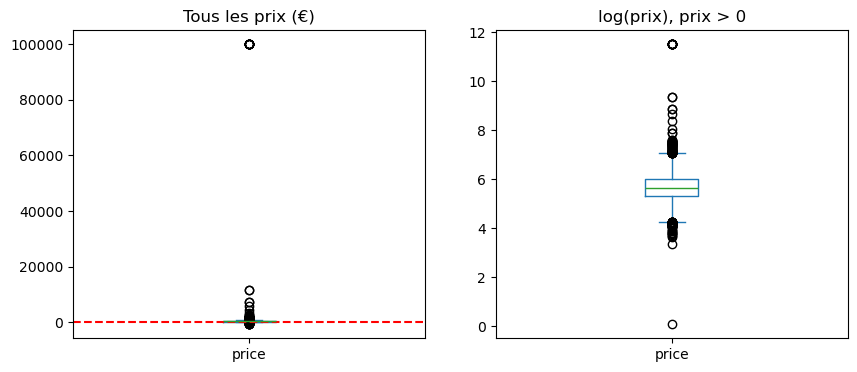

In [50]:
"""Valeurs impossibles : cherchez systématiquement les valeurs qui ne peuvent pas exister
(un prix, une capacité ou une durée qui n’ont pas de sens, une note hors de son échelle,
des dates incohérentes entre elles ou postérieures à la collecte, des coordonnées hors de la
ville, un avis rattaché à une annonce qui n’existe pas…). Pour chacune, décidez : corriger
(si la bonne valeur peut être retrouvée de façon fiable), neutraliser (valeur manquante)
ou écarter la ligne.
"""

import matplotlib.pyplot as plt
import numpy as np

prix = nouvelle_table_propre['price']
masque = prix > 0

print("Prix ≤ 0 :", (prix <= 0).sum())          
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

prix.plot(kind='box', ax=axes[0], title='Tous les prix (€)')
axes[0].axhline(0, color='red', linestyle='--')    

np.log(prix[masque]).plot(kind='box', ax=axes[1], title='log(prix), prix > 0')

plt.show()

In [ ]:
"""Valeurs aberrantes (possibles mais extrêmes) : au minimum price et minimum_nights.
– Détection par quantiles et boxplot.
– Règle de traitement justifiée.
• Lignes écartées conservées dans un DataFrame de rejet, avec le motif.
• Tableau des anomalies détectées : fichier, type d’anomalie, colonnes, nombre de lignes,
traitement appliqué.
Barème. doublons exacts et partiels traités, règle justifiée (1,5) ; valeurs impossibles détectées et
traitées (1,5) ; valeurs aberrantes, rejets tracés et tableau des anomalies (2)"""

In [ ]:
"""B1
• Créez au moins 5 variables, par exemple :

– annonce active (définition à justifier) ; number_of_reviews_ltm ,last_review, availability_365 > 0

– hôte multi-annonces (seuil à justifier): calculated_host_listings_count>2

– logement entier ; room_type

– prix par personne ; price/accommodates

– ancienneté de l’hôte ;hosts_time_as_host_months 

– nombre d’équipements, et indicatrices pour les équipements que vous étudierez en C1 ;amenities

– durée minimale au regard du seuil réglementaire de votre ville ;minimum_nights

– statut de la licence: license




B2


from reviews: 

number_of_reviews
ast_review
number_of_reviews_ltm


Q1 – Taille et dynamique du marché

• nombre et part des annonces actives selon votre définition, et comment ce chiffre change
avec une autre définition raisonnable ;
number_of_reviews_ltm ,last_review, availability_365 > 0

• saisonnalité de l’activité (nombre d’avis par mois) : quels mois portent le revenu ?
fichier review 


Q2 – Concurrence

• part des annonces et du revenu estimé détenue par les hôtes multi-annonces ;   
annonces actives (number_of_reviews_ltm ,last_review, availability_365 > 0)/ 
calculated_host_listings_count -identifier multi annonces 


• part détenue par les 10 % d’hôtes les plus actifs ; 
annonces actives-choisir les 10% (group by host_id) par  estimated_revenue_l365d  

• courbe de Lorenz et indice de Gini du revenu par hôte (méthode en annexe D).


Q3 – Où investir

• par quartier : 

nombre d’annonces:group by 'neighbourhood_cleansed' compter id 

prix médian:'price'pour median

occupation médiane :'estimated_occupancy_l365d'

revenu médian: estimated_revenue_l365d par id par 'neighbourhood_cleansed' 'room_type'
(pivot_table avec room_type) ;

• densité de concurrence : annonces actives pour 1 000 habitants (ville, ou quartiers si vous
avez la donnée) ;
id ,  number_of_reviews_ltm ,last_review, availability_365 


• classement argumenté des quartiers les plus favorables.
revenu: 'neighbourhood_cleansed' ou 'estimated_revenue_l365d' est haut 
occupancy: 'estimated_occupancy_l365d'
concurrence: densité pas haut 


Q4 – Cadre légal

• part des annonces avec et sans valeur dans license, et formats rencontrés ;
'license'

• lien avec la durée minimale de séjour et le type de logement ;
'room_type'   'minimum_nights', 'license'

• cohérence avec la règle locale trouvée en A1 ;

• conséquence pour l’investisseur : quel modèle de location est possible (nuitée avec
enregistrement, moyenne durée…), et à quelles conditions.


"""













In [ ]:
"""C1 

Question : quels équipements augmentent réellement le prix ou le revenu ?

1. Choisissez 8 à 12 équipements plausibles pour un investisseur : parking, climatisation,
lave-vaisselle, arrivée autonome, balcon ou terrasse, espace de travail, foyer, piscine, spa,
vue… Créez une indicatrice par équipement à partir de amenities.
'amenities'


2. Comparaison naïve : pour chaque équipement, comparez le prix médian et le revenu
médian des annonces qui l’ont et de celles qui ne l’ont pas.
'price', 'estimated_revenue_l365d'

3. Comparaison à annonces comparables : refaites la comparaison à l’intérieur de groupes
homogènes, par exemple par classe de capacité (1-2, 3-4, 5-6, 7 personnes et plus), puis
faites la moyenne des écarts, pondérée par la taille des groupes. Méthode en annexe E.
'amenities','price', 'estimated_revenue_l365d', 'accommodates'


4. Niveau avancé : régression linéaire du logarithme du prix sur les équipements, la
capacité, le nombre de chambres et le quartier (LinearRegression). Chaque coeﬀicient
se lit comme une prime en pourcentage.
'amenities','price', 'estimated_revenue_l365d', 'accommodates', 'bedrooms', 'neighbourhood_cleansed'


5. Présentez un tableau final : équipement, part des annonces équipées, prime naïve, prime
à annonces comparables (et prime de la régression si vous l’avez faite).


6. Commentez les écarts entre les méthodes. Pourquoi la comparaison naïve surestime-t-
elle souvent la prime ? Quels équipements recommandez-vous, et avec quel niveau de
confiance ?


""""